<a href="https://colab.research.google.com/github/daisymayorga-galtechs/Occupational-Employment-and-Wage-Statistics/blob/main/modesto_msa_2009_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

# Load the dataset
file_path = '/content/modesto_msa_2009_2026.csv'
df = pd.read_csv(file_path)

# Display basic information
print("=== Dataset Info ===")
df.info()

# Display preview
print("\n=== Preview (First 5 Rows) ===")
display(df.head())

# Basic stats for numeric columns
print("\n=== Numerical Summary ===")
display(df.describe(include='all'))

# Unique values in key categorical columns
categorical_cols = ['Area Type', 'Area Name', 'Year', 'Quarter', 'Industry Name']
print("\n=== Unique Values in Key Columns ===")
for col in categorical_cols:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values. Examples: {df[col].unique()[:5]}")

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 16 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Area Type                              16637 non-null  object 
 1   Area Name                              16637 non-null  object 
 2   Year                                   16637 non-null  int64  
 3   Quarter                                16637 non-null  object 
 4   Industry Name                          16637 non-null  object 
 5   Standard Occupational Classification   16637 non-null  int64  
 6   Occupational Title                     16637 non-null  object 
 7   Wage Type                              16637 non-null  object 
 8   Number of Employed                     16181 non-null  float64
 9   Mean Wage                              16410 non-null  float64
 10  10th Percentile Wage                   16412 non-

,Area Type,Area Name,Year,Quarter,Industry Name,Standard Occupational Classification,Occupational Title,Wage Type,Number of Employed,Mean Wage,10th Percentile Wage,25th Percentile Wage,50th Percentile (Median) Wage,75th Percentile Wage,90th Percentile Wage,Mean Relative Standard Error for Wage
0,Metropolitan Area,Modesto MSA,2009,1st Qtr,"Total, All Industries",0,"Total, All Occupations",Hourly wage,165020.0,19.50,8.53,10.16,15.43,24.05,36.43,1.59
1,Metropolitan Area,Modesto MSA,2009,1st Qtr,"Total, All Industries",0,"Total, All Occupations",Annual wage or salary,165020.0,40566.24,17746.27,21124.35,32089.15,50020.79,75788.34,1.59
2,Metropolitan Area,Modesto MSA,2009,1st Qtr,"Total, All Industries",110000,Management Occupations,Hourly wage,6780.0,42.32,18.05,26.43,37.98,51.45,72.13,2.16
3,Metropolitan Area,Modesto MSA,2009,1st Qtr,"Total, All Industries",110000,Management Occupations,Annual wage or salary,6780.0,88026.48,37539.44,54970.89,78990.99,107018.32,150038.36,2.16
4,Metropolitan Area,Modesto MSA,2009,1st Qtr,"Total, All Industries",111011,Chief Executives,Hourly wage,230.0,0.00,43.12,56.29,78.54,0.00,0.00,4.64



=== Numerical Summary ===


,Area Type,Area Name,Year,Quarter,Industry Name,Standard Occupational Classification,Occupational Title,Wage Type,Number of Employed,Mean Wage,10th Percentile Wage,25th Percentile Wage,50th Percentile (Median) Wage,75th Percentile Wage,90th Percentile Wage,Mean Relative Standard Error for Wage
count,16637,16637,16637.000000,16637,16637,16637.000000,16637,16637,16181.000000,16410.000000,16412.000000,16404.000000,16382.000000,16342.000000,16234.000000,16539.000000
unique,1,1,NaN,1,2,NaN,815,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Metropolitan Area,Modesto MSA,NaN,1st Qtr,"Total, All Industries",NaN,"Packers and Packagers, Hand",Annual wage or salary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,16637,16637,NaN,16637,13735,NaN,36,7863,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2017.613572,NaN,NaN,339730.440224,NaN,NaN,1125.179532,30115.871452,19006.094215,22616.343118,27850.480316,34320.544058,40233.742200,5.428286
std,NaN,NaN,5.207481,NaN,NaN,139049.953031,NaN,NaN,8463.169948,38208.102473,23055.841502,27969.942012,34690.096441,42815.341005,50522.933443,4.281339
min,NaN,NaN,2009.000000,NaN,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,2013.000000,NaN,NaN,211022.000000,NaN,NaN,50.000000,23.830000,15.907500,18.290000,22.440000,27.512500,31.432500,2.700000
50%,NaN,NaN,2018.000000,NaN,NaN,352012.000000,NaN,NaN,140.000000,19105.445000,17042.760000,17292.720000,8511.945000,95.970000,92.595000,4.300000
75%,NaN,NaN,2022.000000,NaN,NaN,472073.000000,NaN,NaN,390.000000,50935.775000,33799.957500,38731.562500,47890.762500,59733.755000,69955.187500,6.800000



=== Unique Values in Key Columns ===
Area Type: 1 unique values. Examples: ['Metropolitan Area']
Area Name: 1 unique values. Examples: ['Modesto MSA']
Year: 18 unique values. Examples: [2009 2010 2011 2012 2021]
Quarter: 1 unique values. Examples: ['1st Qtr']
Industry Name: 2 unique values. Examples: ['Total, All Industries' 'Total, All Industry']


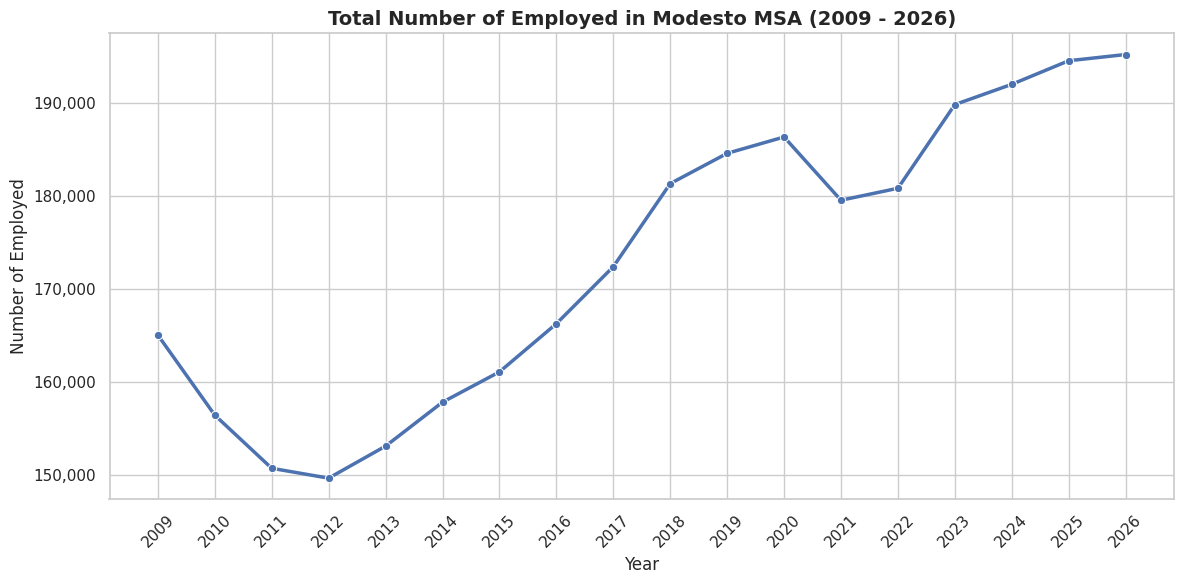

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize occupational titles to find the overall totals
# We check for variations of "total" (e.g., "Total, All Occupations", "Total all occupations")
total_employment = df[
    df['Occupational Title'].str.lower().str.contains('total, all occupations|total all occupations', na=False)
]

# We only want one entry per year/wage type to avoid duplicate count.
# Since 'Number of Employed' is the same for Hourly and Annual rows, we drop duplicates based on Year
total_employment_yearly = total_employment.drop_duplicates(subset=['Year']).sort_values('Year')

# Plot the trend
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
sns.lineplot(data=total_employment_yearly, x='Year', y='Number of Employed', marker='o', color='b', linewidth=2.5)

plt.title('Total Number of Employed in Modesto MSA (2009 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Employed', fontsize=12)
plt.xticks(total_employment_yearly['Year'], rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.show()

=== Top 10 Growing Jobs in Modesto MSA (2022 to 2026) ===


Year,Occupational Title,2022,2026,Absolute Growth,Percentage Growth (%)
0,Healthcare Support Occupations,11620.0,14850.0,3230.0,27.796902
1,Educational Instruction and Library Occupations,12210.0,15310.0,3100.0,25.389025
2,Food Preparation and Serving-Related Occupations,15300.0,18400.0,3100.0,20.261438
3,Home Health and Personal Care Aides,6740.0,9160.0,2420.0,35.905045
4,Business and Financial Operations Occupations,6300.0,8180.0,1880.0,29.841270
5,Transportation and Material Moving Occupations,19950.0,21700.0,1750.0,8.771930
6,"Substitute Teachers, Short-Term",630.0,1990.0,1360.0,215.873016
7,Personal Care and Service Occupations,3060.0,4090.0,1030.0,33.660131
8,"Teaching Assistants, Except Postsecondary",2540.0,3470.0,930.0,36.614173
9,Community and Social Services Occupations,4430.0,5200.0,770.0,17.381490


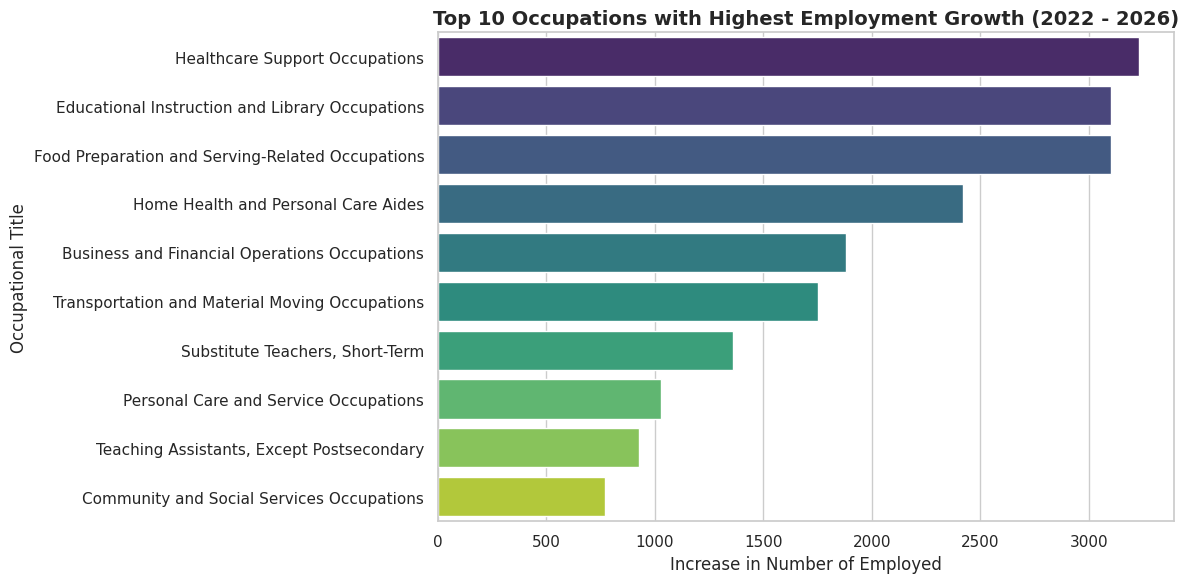

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for years 2022 and 2026
df_filtered = df[df['Year'].isin([2022, 2026])].copy()

# Drop general 'Total' categories to focus on specific occupations
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_filtered = df_filtered[~df_filtered['Occupational Title'].str.lower().isin(exclude_keywords)]

# Aggregate to handle cases where multiple entries exist for the same year and title
# This also solves the issue of different Wage Types causing duplication
df_clean = df_filtered.groupby(['Occupational Title', 'Year'])['Number of Employed'].mean().reset_index()

# Pivot the data to get employment for 2022 and 2026 side-by-side
pivot_df = df_clean.pivot(index='Occupational Title', columns='Year', values='Number of Employed').dropna()

# Calculate Absolute Growth and Percentage Growth
pivot_df['Absolute Growth'] = pivot_df[2026] - pivot_df[2022]
pivot_df['Percentage Growth (%)'] = (pivot_df['Absolute Growth'] / pivot_df[2022]) * 100

# Sort by absolute growth to find the top 10 growing jobs
top_growing_jobs = pivot_df.sort_values(by='Absolute Growth', ascending=False).head(10).reset_index()

# Display the table
print("=== Top 10 Growing Jobs in Modesto MSA (2022 to 2026) ===")
display(top_growing_jobs[['Occupational Title', 2022, 2026, 'Absolute Growth', 'Percentage Growth (%)']])

# Plot the top growing jobs
plt.figure(figsize=(12, 6))
sns.barplot(data=top_growing_jobs, x='Absolute Growth', y='Occupational Title', palette='viridis', hue='Occupational Title', legend=False)
plt.title('Top 10 Occupations with Highest Employment Growth (2022 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Increase in Number of Employed', fontsize=12)
plt.ylabel('Occupational Title', fontsize=12)
plt.tight_layout()
plt.show()

=== Top 10 Occupations by Employment Volume in Modesto MSA (2026) ===


,Occupational Title,Number of Employed
0,Transportation and Material Moving Occupations,21700.0
1,Office and Administrative Support Occupations,18750.0
2,Food Preparation and Serving-Related Occupations,18400.0
3,Sales and Related Occupations,16660.0
4,Educational Instruction and Library Occupations,15310.0
5,Healthcare Support Occupations,14850.0
6,Healthcare Practitioners and Technical Occupat...,13290.0
7,Production Occupations,12070.0
8,Management Occupations,10400.0
9,Home Health and Personal Care Aides,9160.0


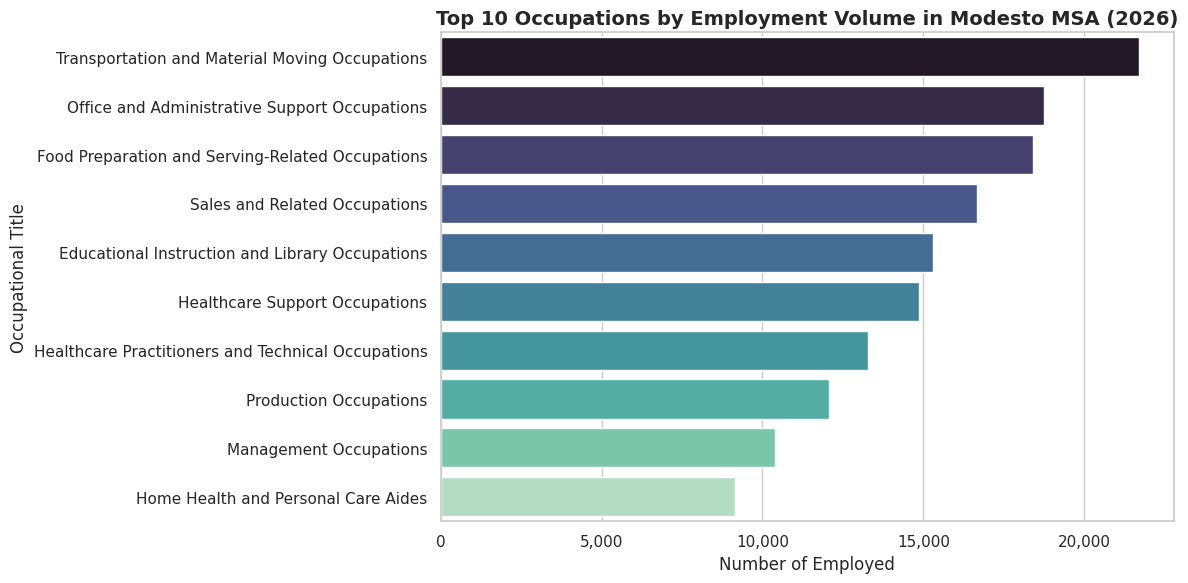

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify the latest year in the dataset
latest_year = df['Year'].max()

# Filter dataset for the latest year
df_latest = df[df['Year'] == latest_year].copy()

# Exclude general total/category sums to focus on specific occupational titles
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_latest_clean = df_latest[~df_latest['Occupational Title'].str.lower().isin(exclude_keywords)]

# Aggregate by 'Occupational Title' to get the mean 'Number of Employed'
# (this averages any duplicate records from Hourly/Annual rows)
occupation_volume = df_latest_clean.groupby('Occupational Title')['Number of Employed'].mean().reset_index()

# Sort in descending order and select the top 10
top_10_by_volume = occupation_volume.sort_values(by='Number of Employed', ascending=False).head(10).reset_index(drop=True)

# Display the table
print(f"=== Top 10 Occupations by Employment Volume in Modesto MSA ({latest_year}) ===")
display(top_10_by_volume)

# Plot the top occupations by volume
plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_by_volume, x='Number of Employed', y='Occupational Title', palette='mako', hue='Occupational Title', legend=False)
plt.title(f'Top 10 Occupations by Employment Volume in Modesto MSA ({latest_year})', fontsize=14, fontweight='bold')
plt.xlabel('Number of Employed', fontsize=12)
plt.ylabel('Occupational Title', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.tight_layout()
plt.show()

=== Top 10 Individual Job Titles by Volume in Modesto MSA (2026) ===


,Occupational Title,Number of Employed
0,Home Health and Personal Care Aides,9160.0
1,Fast Food and Counter Workers,6700.0
2,Retail Salespersons,5140.0
3,Cashiers,4890.0
4,Registered Nurses,4850.0
5,"Laborers and Freight, Stock, and Material Move...",4810.0
6,"Farmworkers and Laborers, Crop, Nursery, and G...",4120.0
7,Stockers and Order Fillers,4080.0
8,Heavy and Tractor-Trailer Truck Drivers,3510.0
9,"Teaching Assistants, Except Postsecondary",3470.0


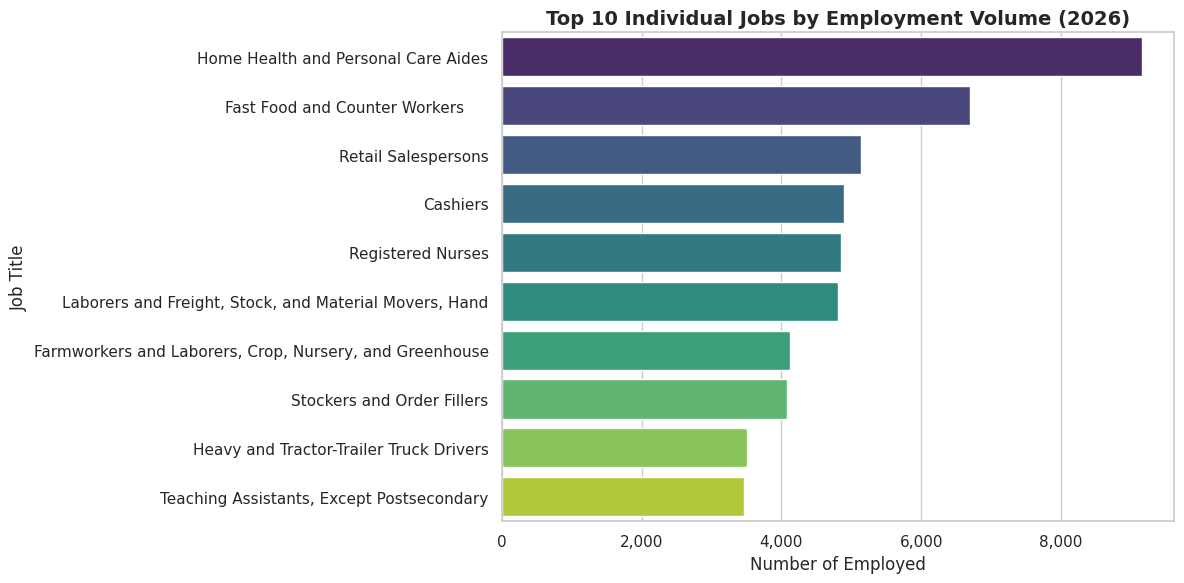

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

latest_year = df['Year'].max()
df_latest = df[df['Year'] == latest_year].copy()

# Exclude totals as well as broad occupational group titles (titles ending with "Occupations")
# to ensure we only look at specific, individual jobs.
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_individual = df_latest[
    (~df_latest['Occupational Title'].str.lower().isin(exclude_keywords)) &
    (~df_latest['Occupational Title'].str.lower().str.endswith('occupations'))
]

# Group and take the mean to clean up any duplicates from Wage Types
individual_volume = df_individual.groupby('Occupational Title')['Number of Employed'].mean().reset_index()

# Get top 10 specific job titles
top_10_individual = individual_volume.sort_values(by='Number of Employed', ascending=False).head(10).reset_index(drop=True)

print(f"=== Top 10 Individual Job Titles by Volume in Modesto MSA ({latest_year}) ===")
display(top_10_individual)

# Plot specific jobs
plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_individual, x='Number of Employed', y='Occupational Title', palette='viridis', hue='Occupational Title', legend=False)
plt.title(f'Top 10 Individual Jobs by Employment Volume ({latest_year})', fontsize=14, fontweight='bold')
plt.xlabel('Number of Employed', fontsize=12)
plt.ylabel('Job Title', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.tight_layout()
plt.show()

=== Tech-Related Individual Job Titles by Volume in Modesto MSA (2026) ===


,Occupational Title,Number of Employed
0,Computer User Support Specialists,360.0
1,Software Developers,300.0
2,"Computer Occupations, All Other",290.0
3,Computer and Information Systems Managers,230.0
4,Network and Computer Systems Administrators,160.0
5,Computer Systems Analysts,140.0
6,Computer Numerically Controlled Tool Operators...,140.0
7,"Computer, Automated Teller, and Office Machine...",90.0
8,Data Scientists,80.0
9,Computer Network Architects,70.0


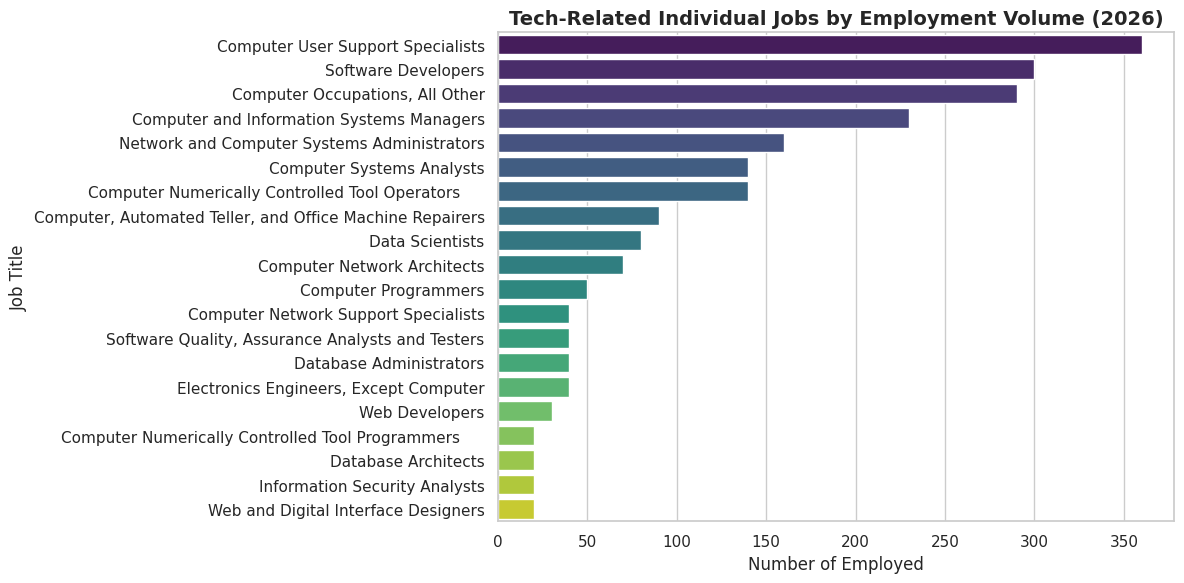

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

latest_year = df['Year'].max()
df_latest = df[df['Year'] == latest_year].copy()

# Exclude totals as well as broad occupational group titles (titles ending with 'Occupations')
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_individual = df_latest[
    (~df_latest['Occupational Title'].str.lower().isin(exclude_keywords)) &
    (~df_latest['Occupational Title'].str.lower().str.endswith('occupations'))
]

# Define tech-related keywords to search for in specific job titles
tech_keywords = [
    'computer', 'software', 'developer', 'programmer', 'network',
    'database', 'information technology', 'system analyst',
    'web', 'data scientist', 'information security', 'hardware engineer'
]

# Filter for tech jobs using regex search on the occupational titles
tech_filter = df_individual['Occupational Title'].str.lower().str.contains('|'.join(tech_keywords), na=False)
df_tech = df_individual[tech_filter].copy()

# Group and take the mean to clean up any duplicates from Wage Types
tech_volume = df_tech.groupby('Occupational Title')['Number of Employed'].mean().reset_index()
tech_volume_sorted = tech_volume.sort_values(by='Number of Employed', ascending=False).reset_index(drop=True)

print(f"=== Tech-Related Individual Job Titles by Volume in Modesto MSA ({latest_year}) ===")
display(tech_volume_sorted)

# Plot the tech jobs if there are any
if not tech_volume_sorted.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(data=tech_volume_sorted, x='Number of Employed', y='Occupational Title', palette='viridis', hue='Occupational Title', legend=False)
    plt.title(f'Tech-Related Individual Jobs by Employment Volume ({latest_year})', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Employed', fontsize=12)
    plt.ylabel('Job Title', fontsize=12)
    plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
    plt.tight_layout()
    plt.show()
else:
    print("No matching tech-related job titles were found with the given keywords.")

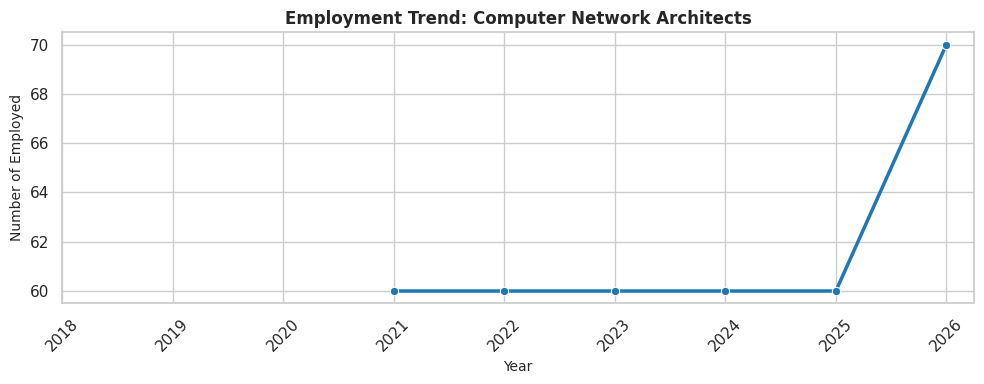

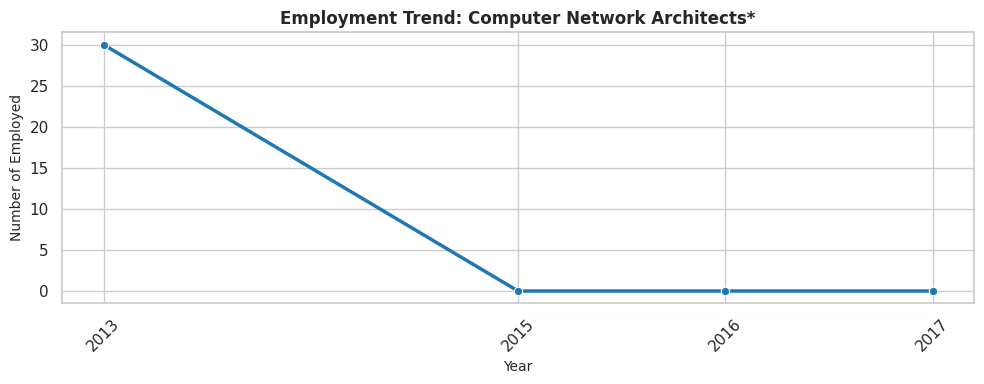

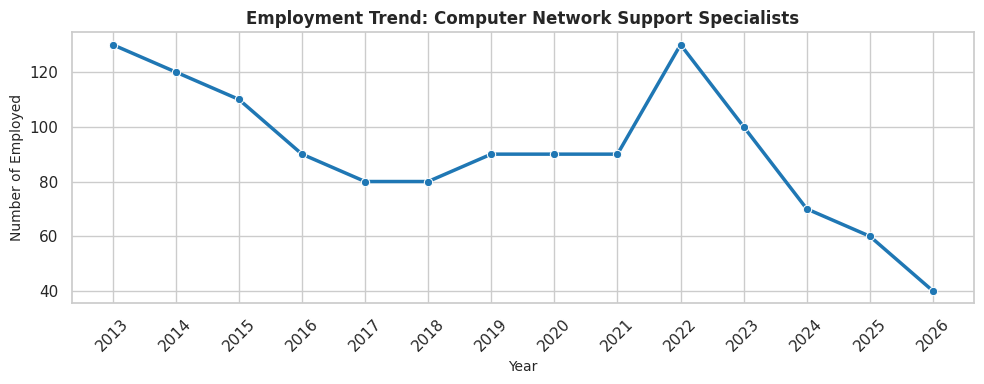

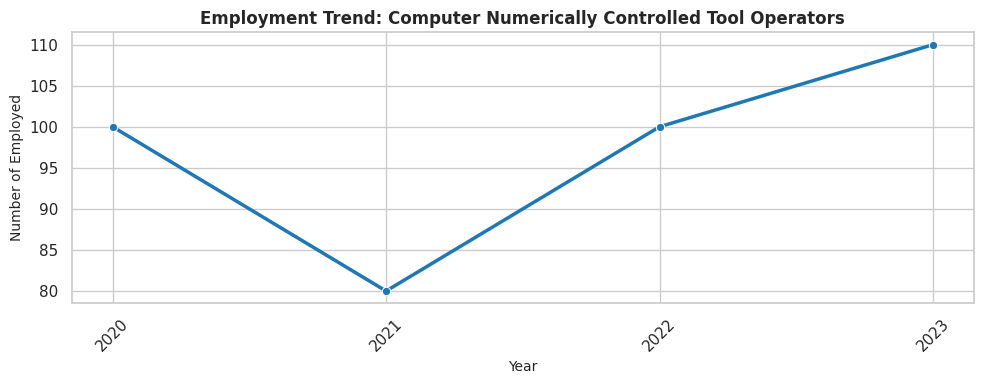

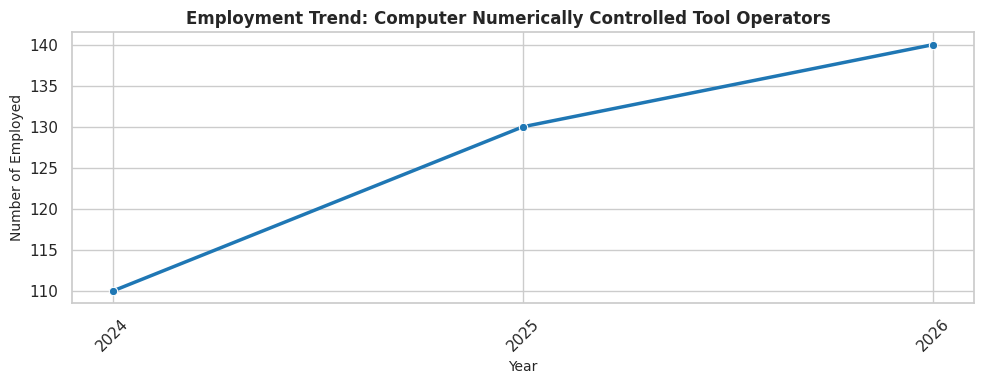

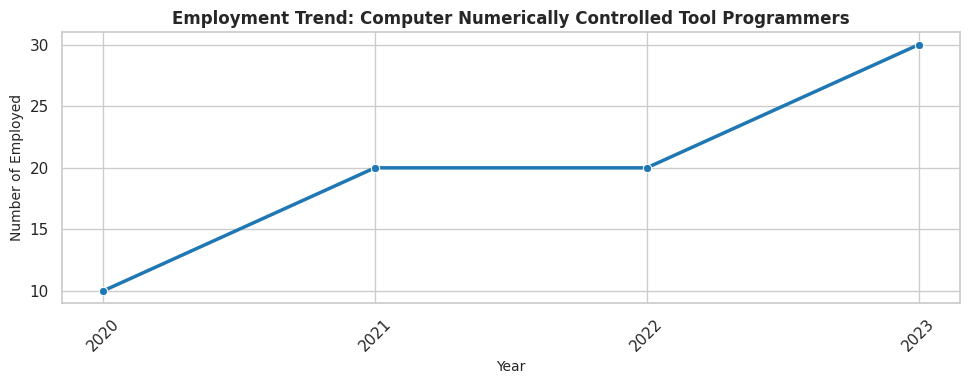

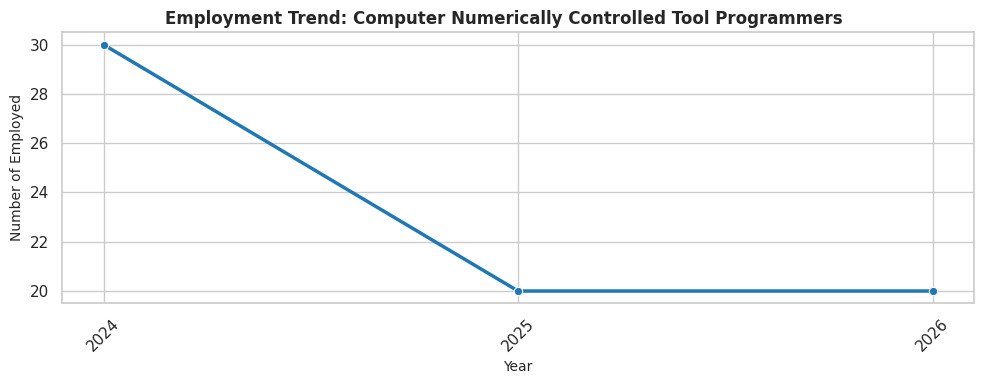

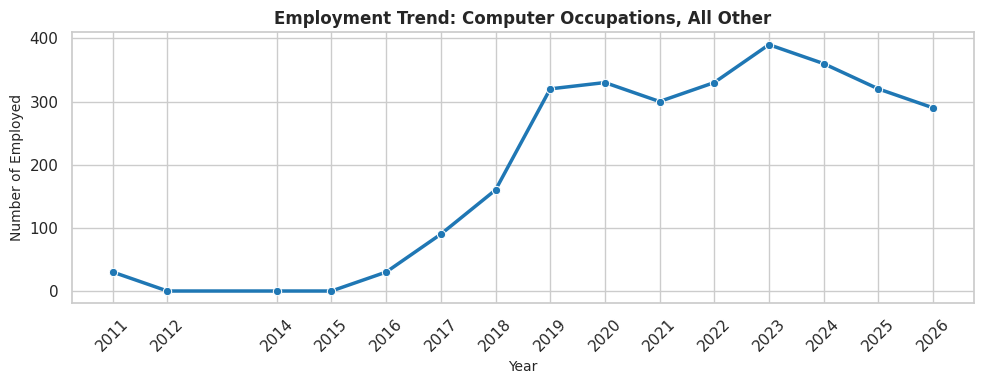

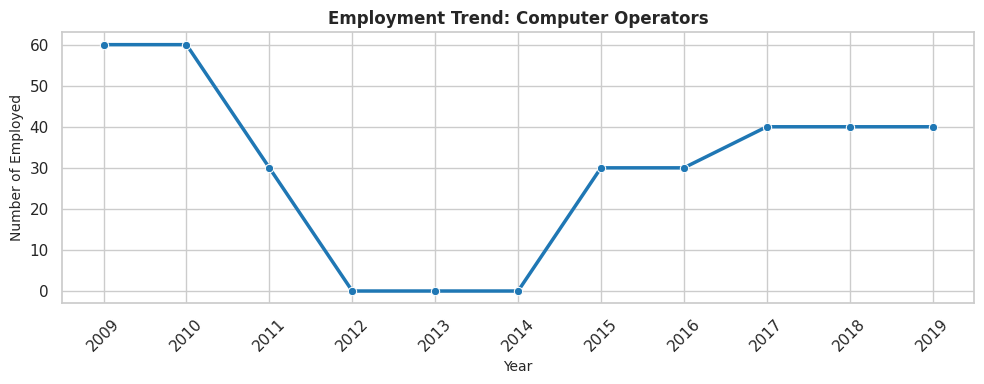

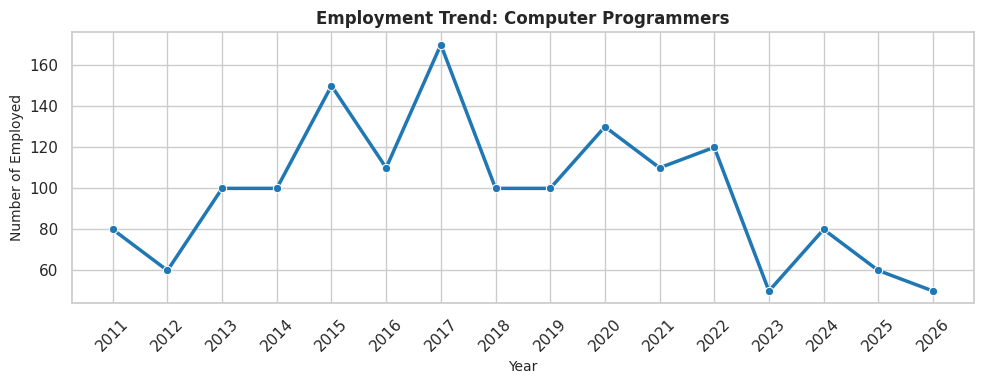

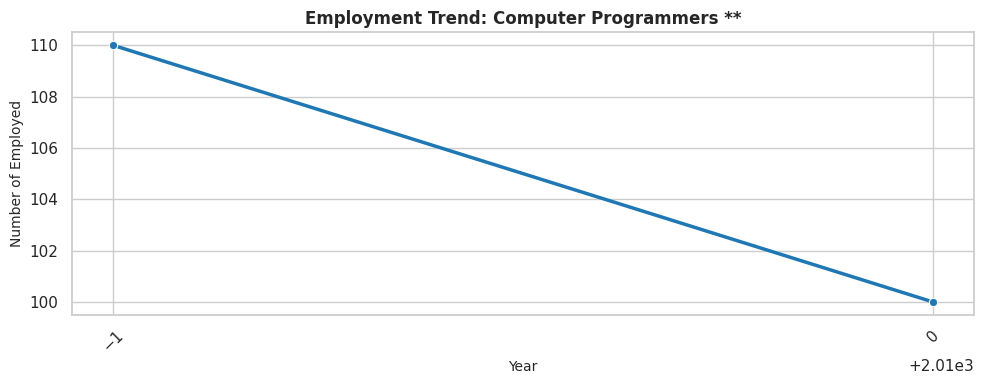

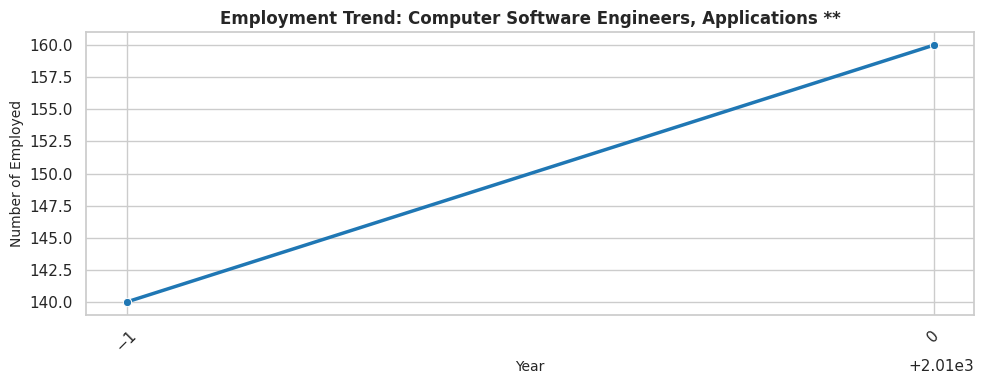

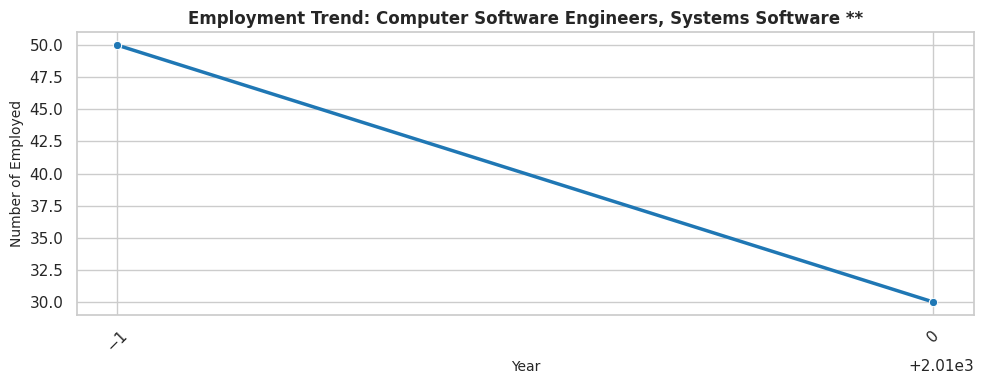

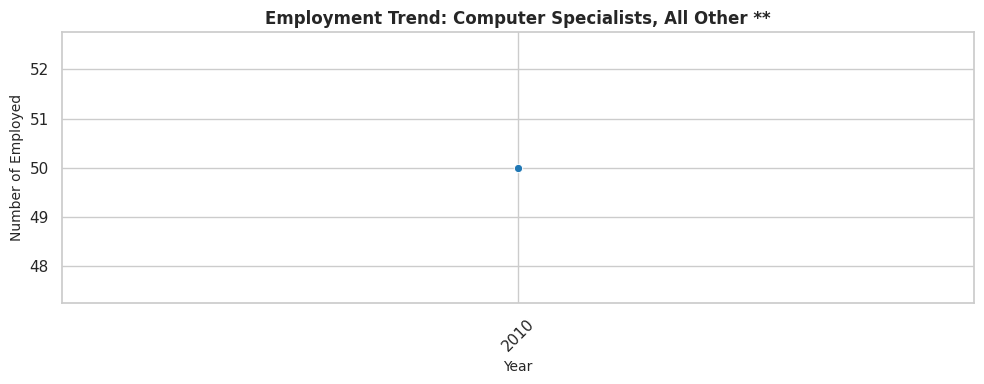

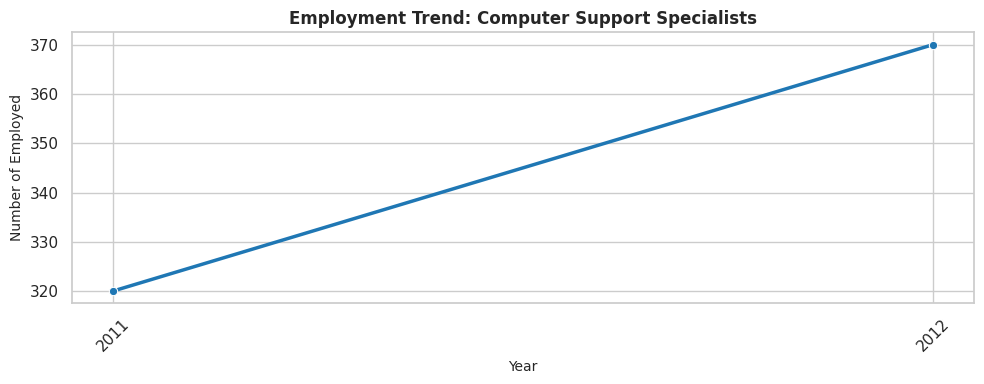

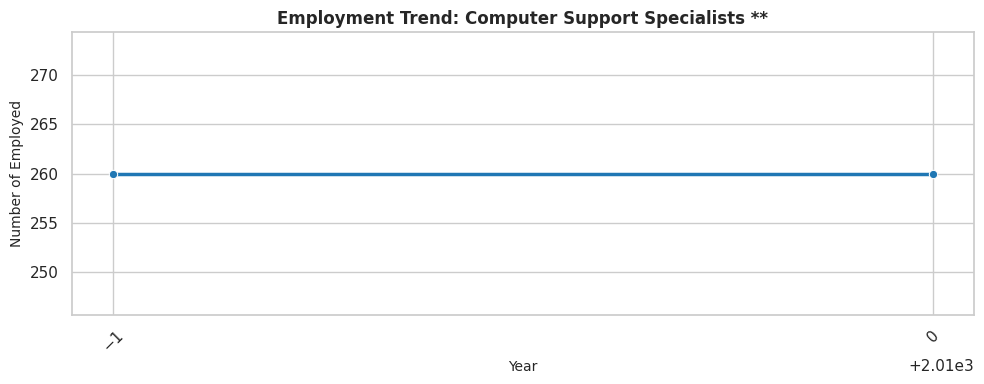

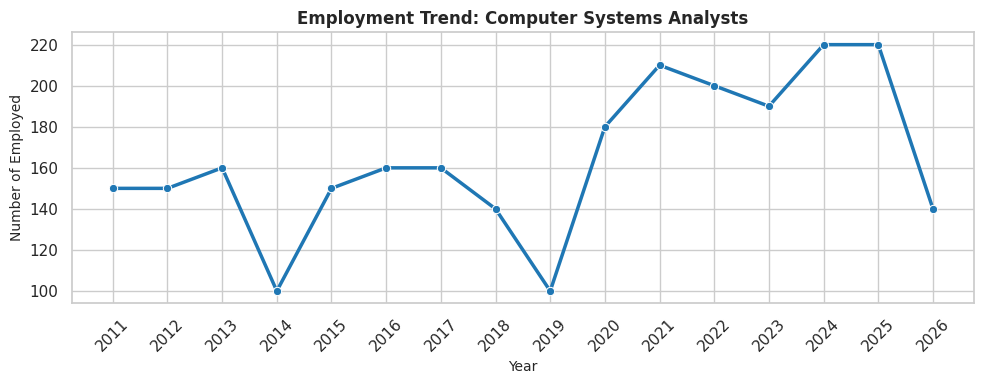

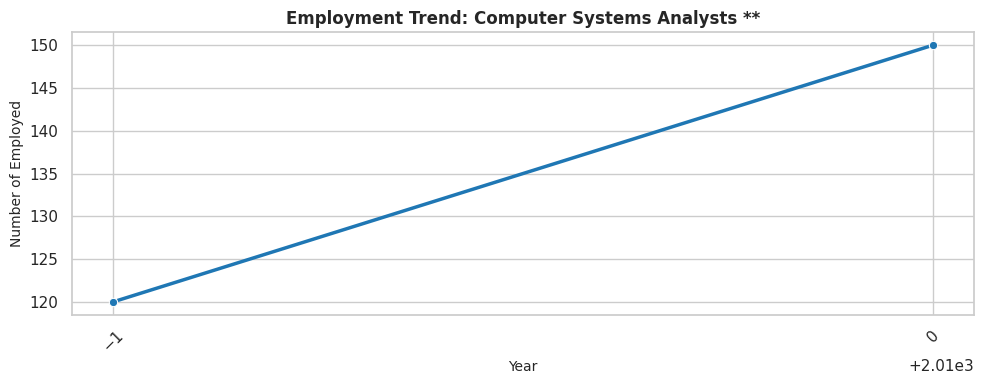

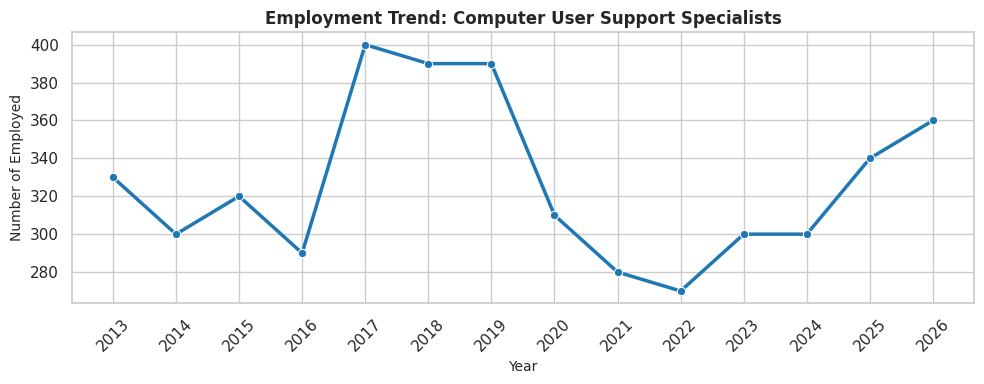

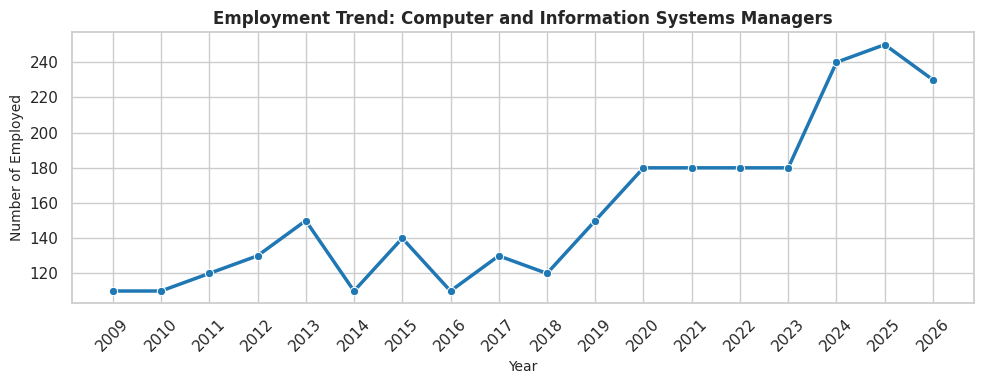

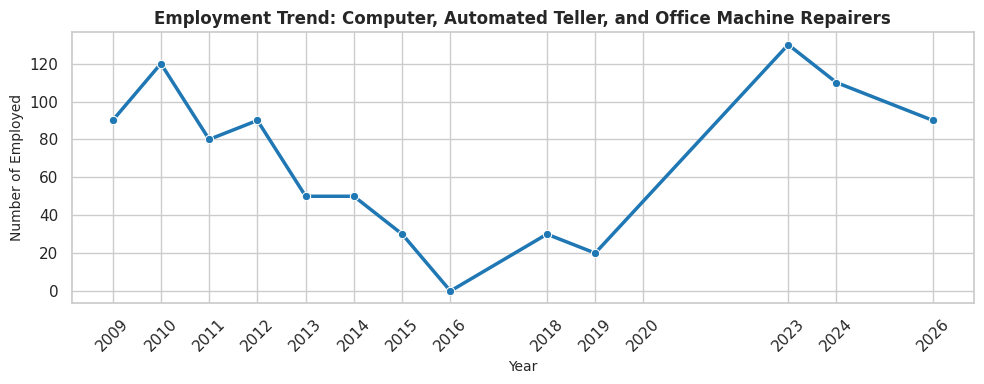

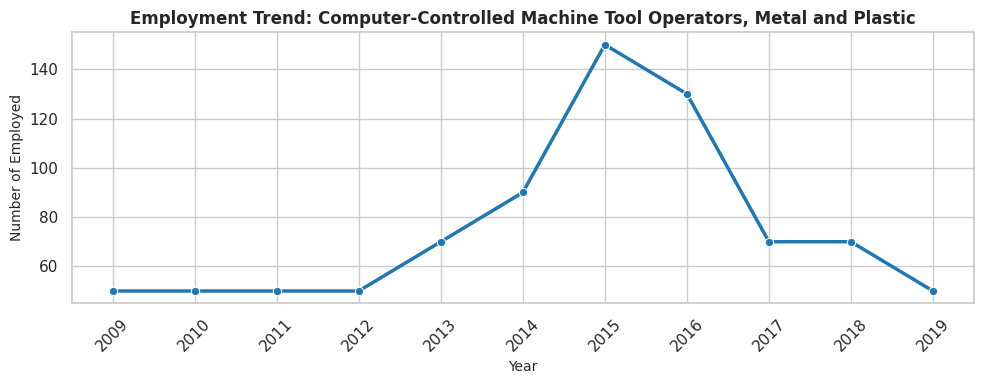

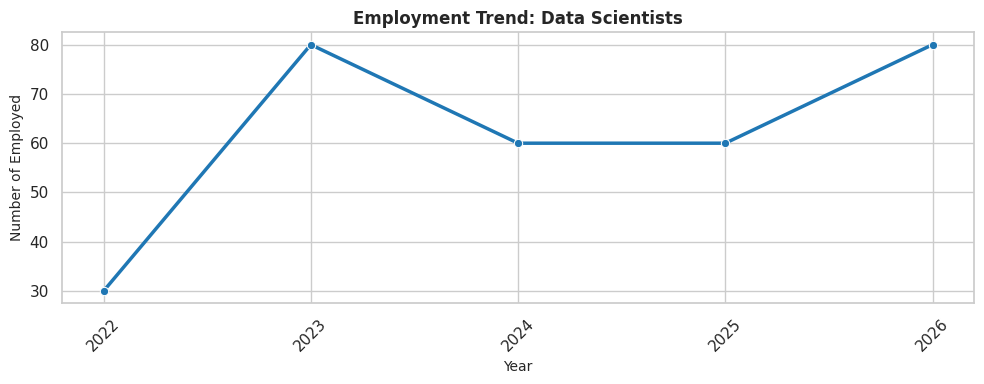

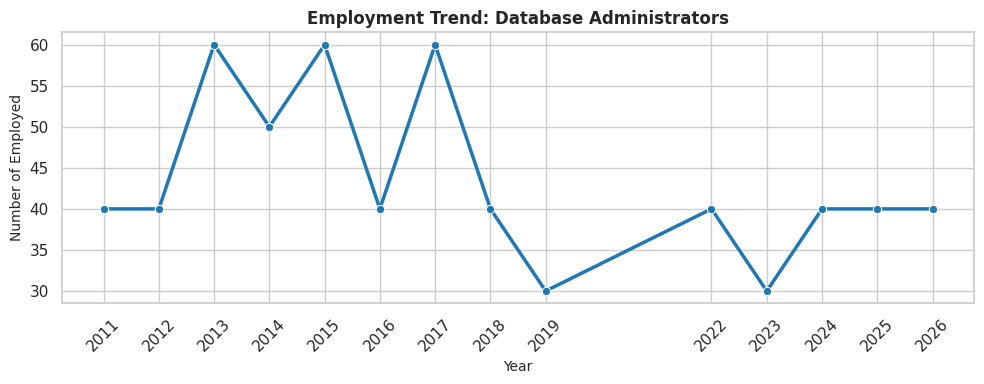

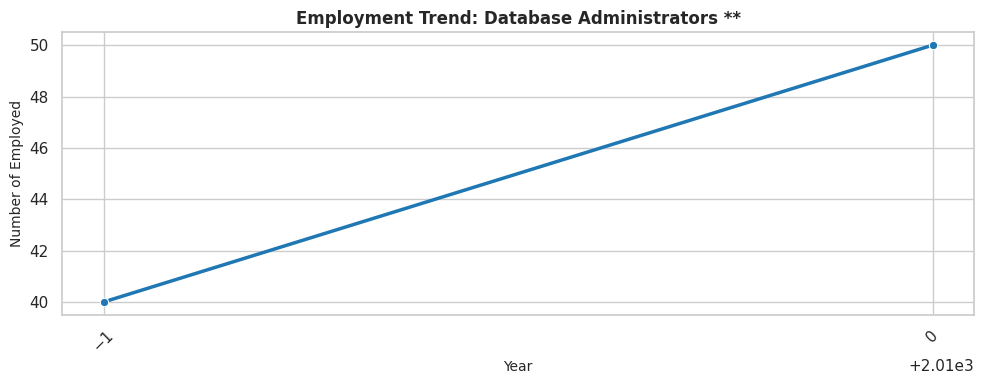

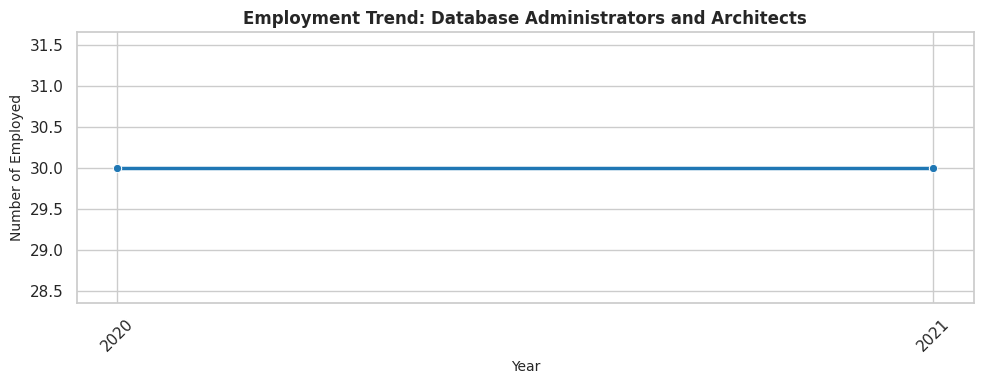

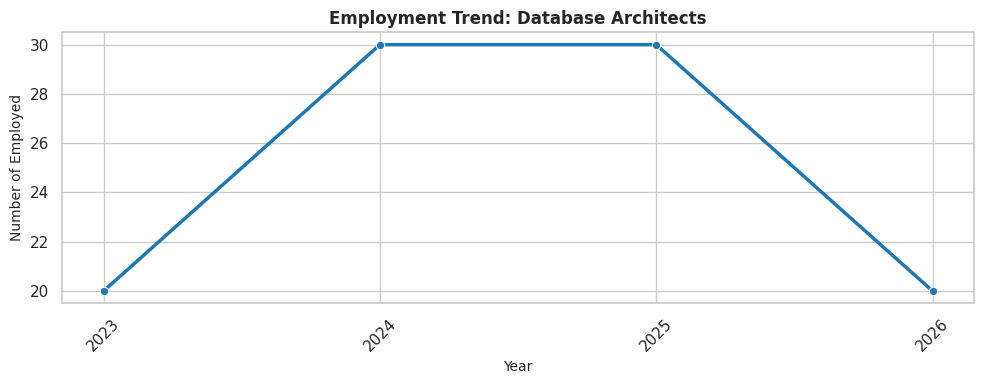

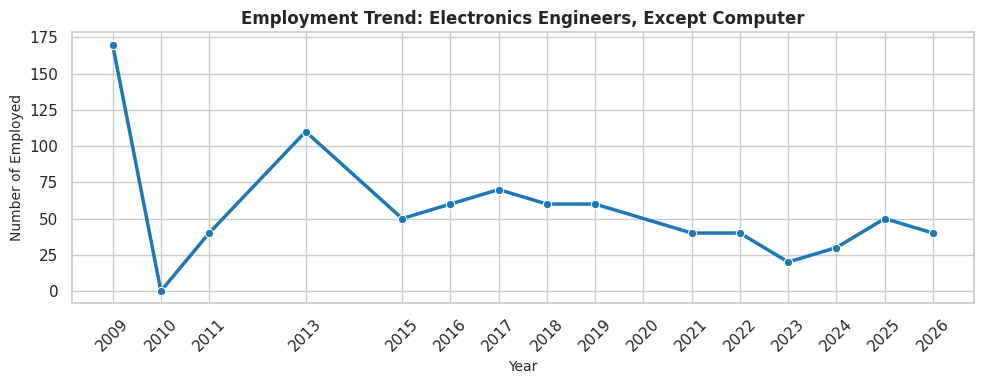

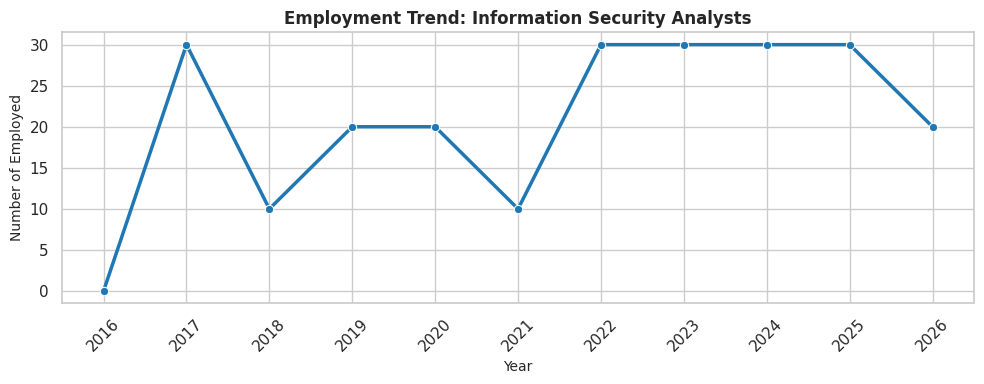

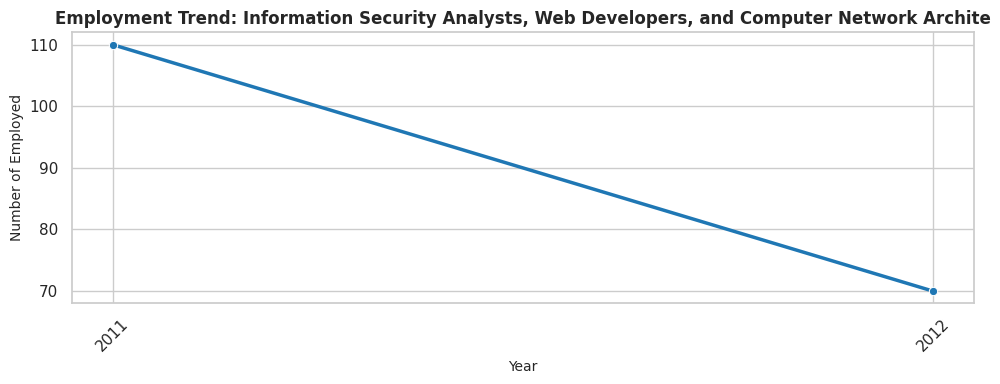

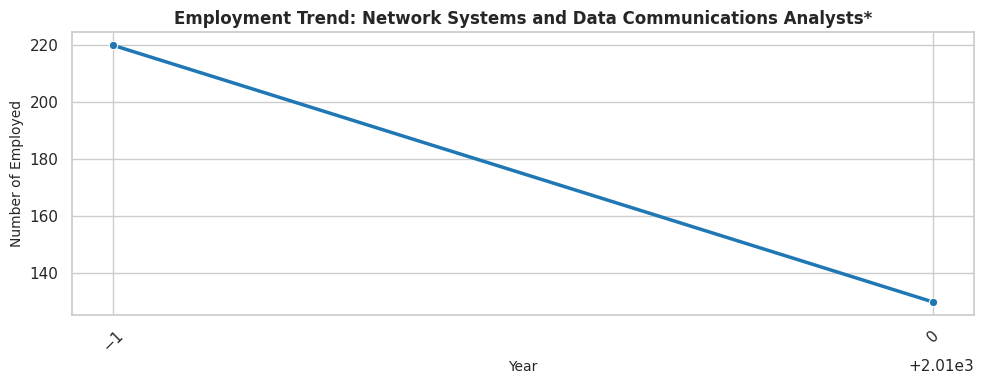

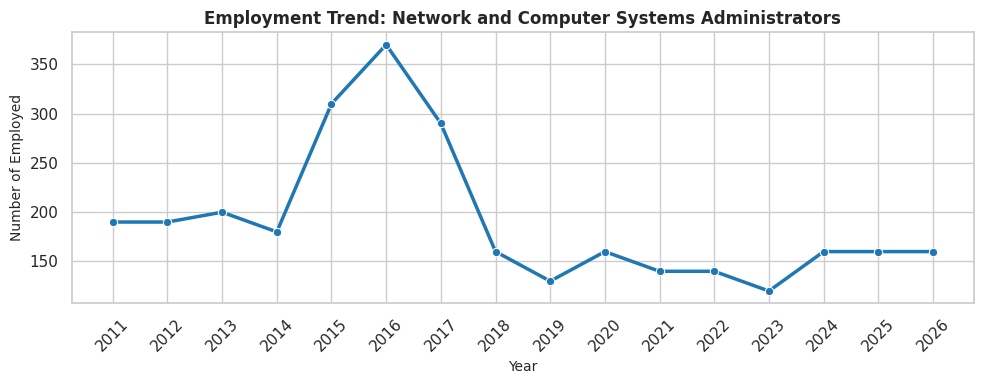

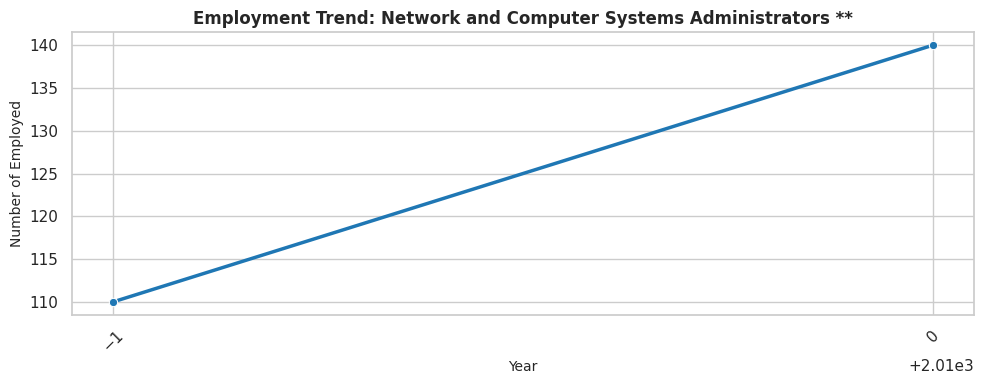

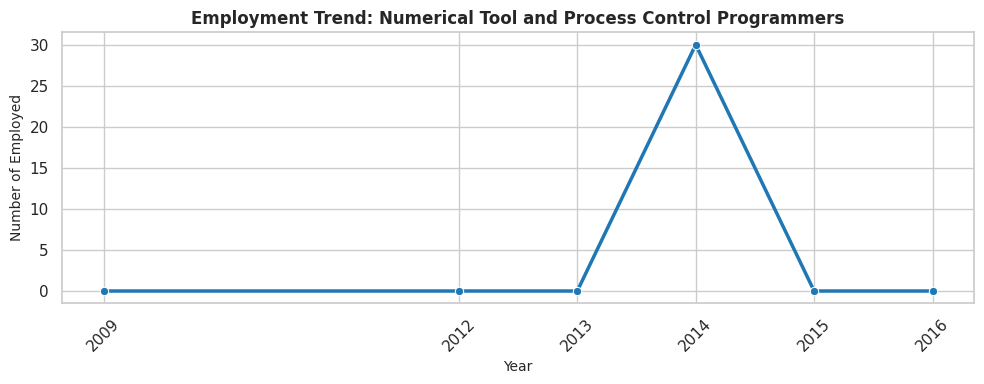

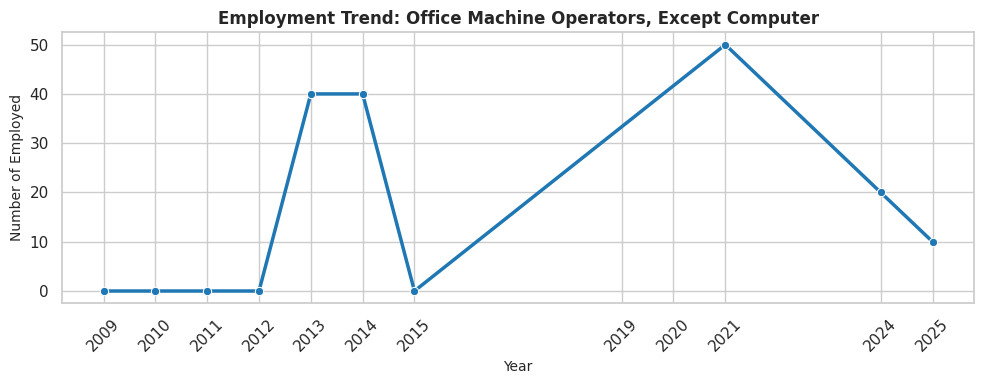

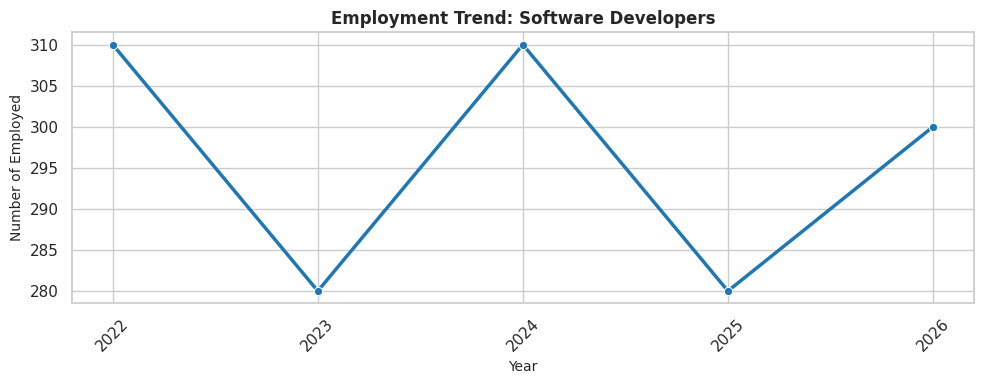

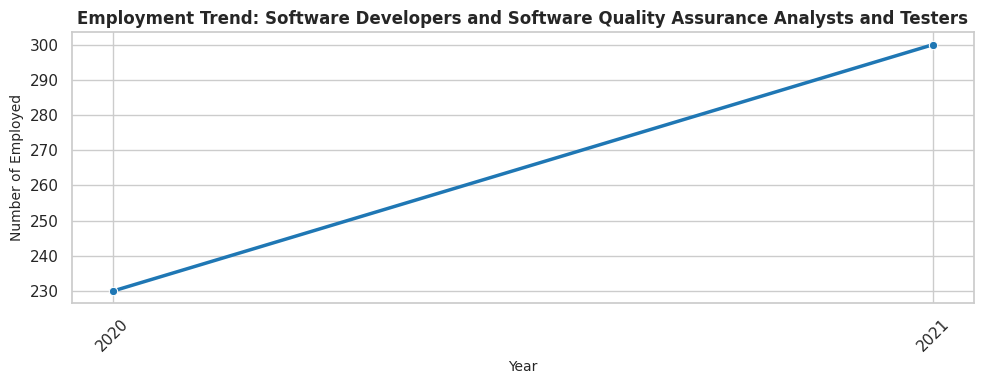

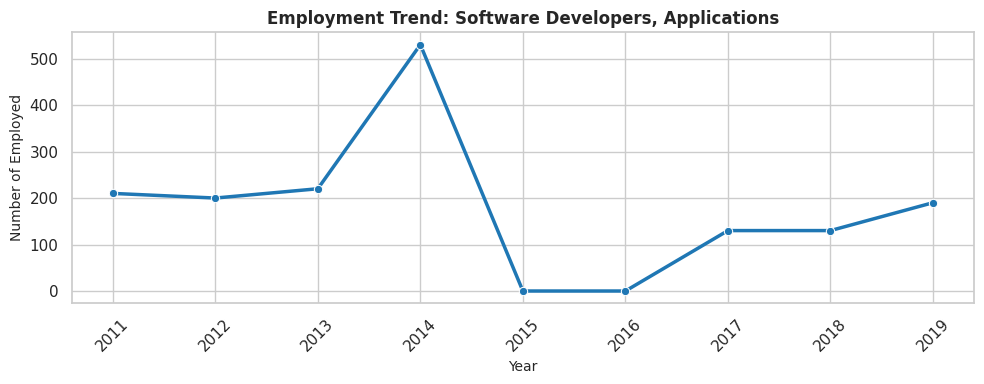

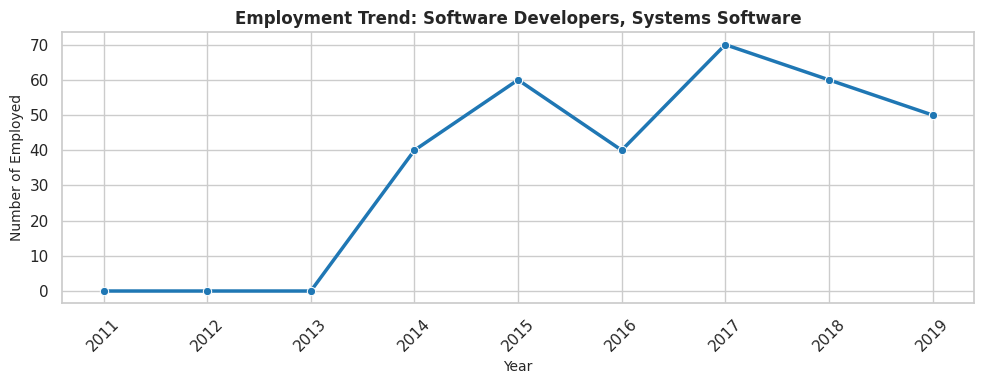

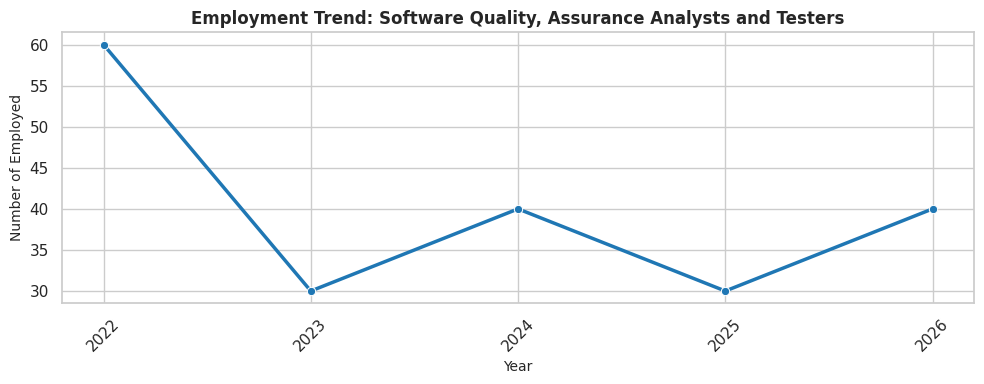

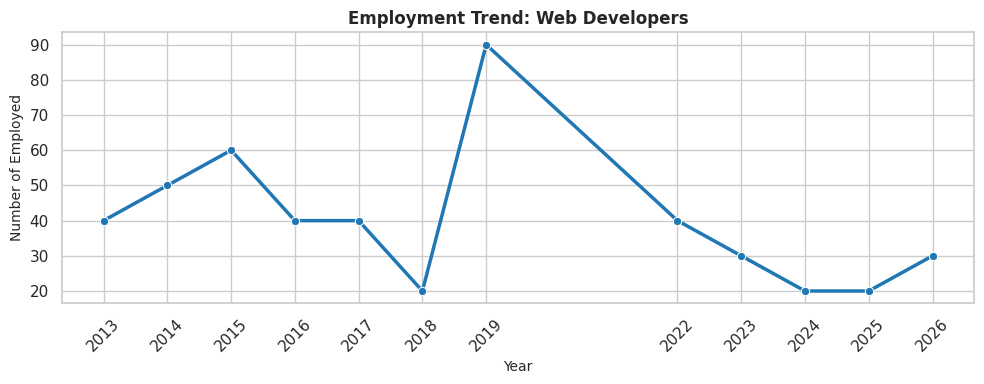

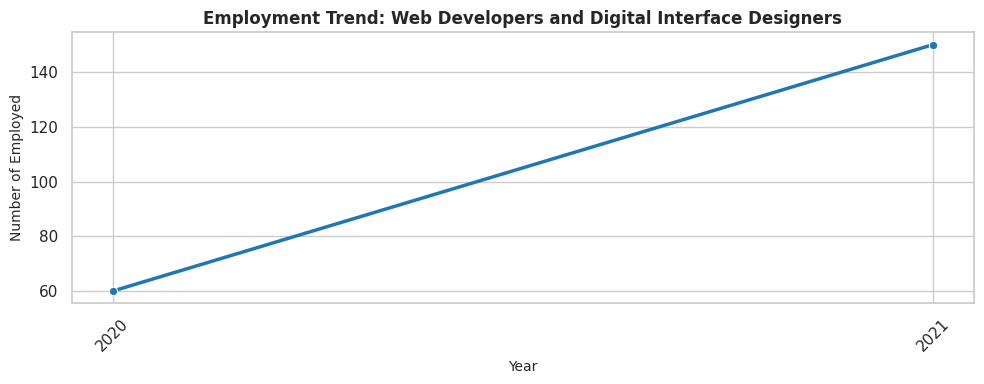

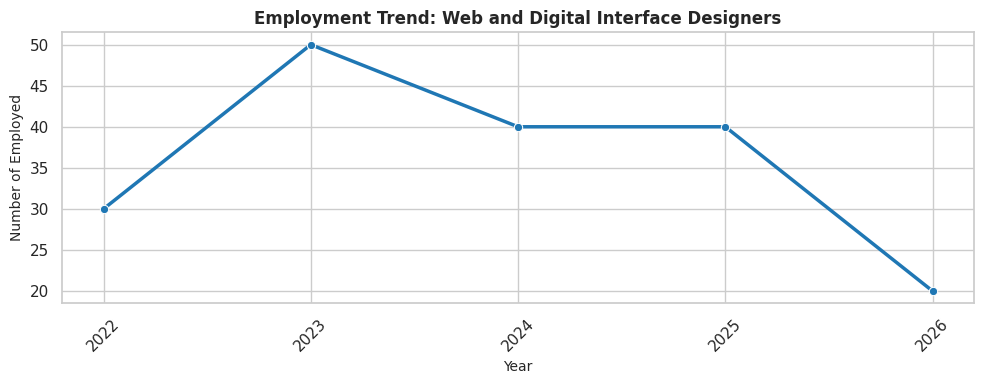

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Standardize to exclude general group totals and find individual occupations
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_individual_all = df[
    (~df['Occupational Title'].str.lower().isin(exclude_keywords)) &
    (~df['Occupational Title'].str.lower().str.endswith('occupations'))
].copy()

# Identify individual tech jobs using keywords on the full historical dataset
tech_keywords = [
    'computer', 'software', 'developer', 'programmer', 'network',
    'database', 'information technology', 'system analyst',
    'web', 'data scientist', 'information security', 'hardware engineer'
]

tech_filter_all = df_individual_all['Occupational Title'].str.lower().str.contains('|'.join(tech_keywords), na=False)
df_tech_all = df_individual_all[tech_filter_all].copy()

# Group by title and year to resolve duplicates and get the mean employment
tech_trends = df_tech_all.groupby(['Occupational Title', 'Year'])['Number of Employed'].mean().reset_index()

# Get list of unique tech occupations found in the historical data
unique_tech_jobs = tech_trends['Occupational Title'].unique()

# Create a plot for each job title in a clean layout
sns.set_theme(style="whitegrid")
for job in sorted(unique_tech_jobs):
    job_data = tech_trends[tech_trends['Occupational Title'] == job].sort_values('Year')

    # Skip plotting if there's no employment data over time
    if job_data['Number of Employed'].dropna().empty:
        continue

    plt.figure(figsize=(10, 4))
    sns.lineplot(data=job_data, x='Year', y='Number of Employed', marker='o', linewidth=2.5, color='#1f77b4')

    plt.title(f"Employment Trend: {job}", fontsize=12, fontweight='bold')
    plt.xlabel("Year", fontsize=10)
    plt.ylabel("Number of Employed", fontsize=10)
    plt.xticks(job_data['Year'].unique(), rotation=45)
    plt.tight_layout()
    plt.show()

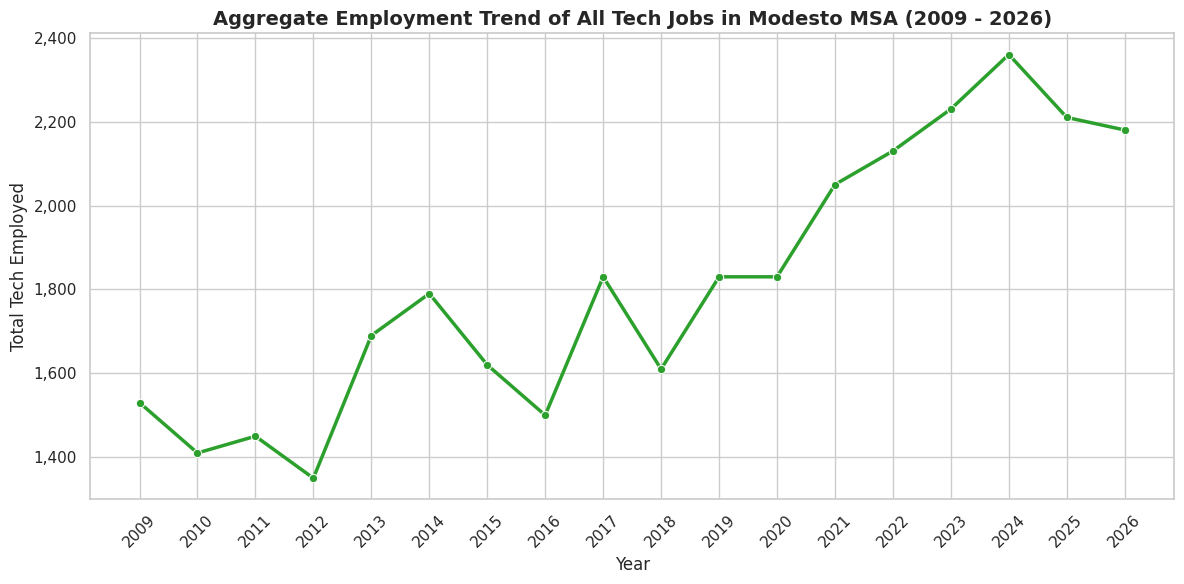

,Year,Number of Employed
0,2009,1530.0
1,2010,1410.0
2,2011,1450.0
3,2012,1350.0
4,2013,1690.0
5,2014,1790.0
6,2015,1620.0
7,2016,1500.0
8,2017,1830.0
9,2018,1610.0


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize and filter to exclude general group totals
exclude_keywords = ['total, all occupations', 'total all occupations', 'total, all industries', 'total, all industry']
df_individual_all = df[
    (~df['Occupational Title'].str.lower().isin(exclude_keywords)) &
    (~df['Occupational Title'].str.lower().str.endswith('occupations'))
].copy()

# Identify individual tech jobs using keywords
tech_keywords = [
    'computer', 'software', 'developer', 'programmer', 'network',
    'database', 'information technology', 'system analyst',
    'web', 'data scientist', 'information security', 'hardware engineer'
]

tech_filter_all = df_individual_all['Occupational Title'].str.lower().str.contains('|'.join(tech_keywords), na=False)
df_tech_all = df_individual_all[tech_filter_all].copy()

# Group by title and year to resolve duplicates first
tech_resolved = df_tech_all.groupby(['Occupational Title', 'Year'])['Number of Employed'].mean().reset_index()

# Now aggregate (sum) all tech jobs together for each year
aggregated_tech_trend = tech_resolved.groupby('Year')['Number of Employed'].sum().reset_index()

# Plot the aggregated trend
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
sns.lineplot(data=aggregated_tech_trend, x='Year', y='Number of Employed', marker='o', linewidth=2.5, color='#2ca02c')

plt.title('Aggregate Employment Trend of All Tech Jobs in Modesto MSA (2009 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Tech Employed', fontsize=12)
plt.xticks(aggregated_tech_trend['Year'].unique(), rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.show()

# Display the aggregated data table
display(aggregated_tech_trend)